In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr, spearmanr
from typing import Literal
import re

In [2]:
df = pd.read_csv("../generated_data/loss_aversion_results_cleaned.csv")
# df = df.drop(columns=["Loss_Aversion_12"]) # Drop this item as the prompt was wrong and the results are not meaningful
used_items = [
    "Loss_Aversion_1",
    "Loss_Aversion_2",
    "Loss_Aversion_3",
    "Loss_Aversion_4",
    "Loss_Aversion_7",
    "Loss_Aversion_8",
    "Loss_Aversion_10",
    "Loss_Aversion_11",
    "Loss_Aversion_13",
    "Loss_Aversion_13_inverse",
    "Loss_Aversion_14",
    "Loss_Aversion_14_inverse"
]

df = df[used_items + ["llm", "persona", "thinking", "experiment_group"]].copy()

In [3]:
prefix = "Loss_Aversion"
invalid_counts = {}

for i in range(1, 15):
    for suffix in ["", "_inverse"]:
        col = f"{prefix}_{i}{suffix}"

        if col not in df.columns:
            continue

        invalid_mask = ~df[col].isin(["A", "B"])
        invalid = df.loc[invalid_mask, [ "llm", col]]

        if not invalid.empty:
            print(col)
            print(invalid)
            print("--------------------")
        counts = df.loc[invalid_mask, "llm"].value_counts()

        for llm, count in counts.items():
                    invalid_counts[llm] = invalid_counts.get(llm, 0) + count

print(pd.Series(invalid_counts, name="total_invalid_responses").sort_values(ascending=False))

Loss_Aversion_1
                  llm                                    Loss_Aversion_1
2664  deepseek-v4-pro  I'm in. Just give me the choice and I'll answe...
--------------------
Loss_Aversion_3
                  llm Loss_Aversion_3
61    deepseek-v4-pro              .B
1378  deepseek-v4-pro             NaN
--------------------
Loss_Aversion_4
                    llm                Loss_Aversion_4
458   deepseek-v4-flash   with exactly one letter: A.A
2792  deepseek-v4-flash                            NaN
--------------------
Loss_Aversion_7
                    llm         Loss_Aversion_7
952   deepseek-v4-flash                     NaN
2518    deepseek-v4-pro   with no explanation.B
--------------------
Loss_Aversion_13
                   llm Loss_Aversion_13
957  deepseek-v4-flash                A
--------------------
Loss_Aversion_13_inverse
                  llm Loss_Aversion_13_inverse
1207  deepseek-v4-pro               I choose A
--------------------
Loss_Aversion_14_inverse


In [4]:
cols = [c for c in df.columns if c.startswith("Loss_Aversion_")]

for col in cols:
    df.loc[~df[col].isin(["A", "B"]), col] = pd.NA

df = df.dropna(subset=cols).copy()

In [5]:
def test_position_bias(
    df,
    group_col="experiment_group",
    group_1=1,
    group_2=2,
    n_bootstraps=10_000,
    seed=1
):
    """
    Test first-position bias in an AB vs BA prompt-inversion design.

    Group 1 = original ordering (AB)
    Group 2 = reversed ordering (BA)

    For each item:
        position_bias = P(A | Group 1) + P(A | Group 2) - 1

    Positive values indicate a tendency to choose the first-listed
    option. Negative values indicate a tendency to choose the
    second-listed option.

    Participants (rows) are resampled as complete units so that
    dependencies between their item responses are preserved.
    """

    rng = np.random.default_rng(seed)
    excluded = {"Loss_Aversion_5", "Loss_Aversion_6", "Loss_Aversion_9"}
    loss_cols = [col for col in df.columns if col.startswith("Loss_Aversion_") and col not in excluded]

    group_1_data = df.loc[df[group_col] == group_1, loss_cols]
    group_2_data = df.loc[df[group_col] == group_2, loss_cols]

    # Observed proportions
    group_1_p_a = (group_1_data == "A").mean()
    group_2_p_a = (group_2_data == "A").mean()

    # item level position bias
    item_position_bias = (group_1_p_a + group_2_p_a - 1)

    item_summary = pd.DataFrame({
        "group_1_p_A": group_1_p_a,
        "group_2_p_A": group_2_p_a,
        "position_bias": item_position_bias
    })

    # overall observed postion bias
    observed_position_bias = item_position_bias.mean()

    bootstrap_item_bias = np.empty((n_bootstraps, len(loss_cols)))
    bootstrap_statistics = np.empty(n_bootstraps)

    n_group_1 = len(group_1_data)
    n_group_2 = len(group_2_data)

    values_group_1 = group_1_data.to_numpy()
    values_group_2 = group_2_data.to_numpy()

    for bootstrap in range(n_bootstraps):

        # Resample complete participants - pick n_group amount of randomly selected participants
        indices_1 = rng.integers(low=0, high=n_group_1, size=n_group_1)
        indices_2 = rng.integers(low=0, high=n_group_2, size=n_group_2)

        sample_group_1 = values_group_1[indices_1]
        sample_group_2 = values_group_2[indices_2]

        # P(A) for every item
        p_a_1 = (sample_group_1 == "A").mean(axis=0)
        p_a_2 = (sample_group_2 == "A").mean(axis=0)

        # Position bias for every item
        item_bias = (p_a_1 + p_a_2 - 1)
        bootstrap_item_bias[bootstrap, :] = item_bias
        # Average across items
        bootstrap_statistics[bootstrap] = item_bias.mean()

    # overall Bootstrap CI
    lower_95CI = np.quantile(bootstrap_statistics, 0.025)
    upper_95CI = np.quantile(bootstrap_statistics, 0.975)

    # Item level CI
    item_summary["lower_95CI"] = np.quantile(bootstrap_item_bias, 0.025, axis=0)
    item_summary["upper_95CI"] = np.quantile(bootstrap_item_bias, 0.975, axis=0)

    overall_summary = pd.DataFrame({
        "position_bias": [observed_position_bias],
        "position_bias_p_A": [((observed_position_bias + 1) / 2)],
        "lower_95CI": [lower_95CI],
        "upper_95CI": [upper_95CI],
        "significant_first_position_bias": [lower_95CI > 0 or upper_95CI < 0]
    })

    return item_summary, overall_summary, bootstrap_statistics

In [6]:
def plot_position_bias(
    item_summary,
    title="Position Bias: AB vs BA Prompt Inversion"
):
    """
    Plot the results of test_position_bias().

    Parameters
    ----------
    item_summary : pd.DataFrame
        First return value from test_position_bias().
    title : str
        Plot title.

    figsize : tuple
        Figure dimensions.
    """

    plot_data = item_summary.copy()
    plot_data["sum_p_A"] = (plot_data["group_1_p_A"] + plot_data["group_2_p_A"])
    items = [item.replace("Loss_Aversion_", "").replace("_inverse", "'") for item in plot_data.index]
    x = np.arange(len(items))

    width = 0.35
    fig, ax = plt.subplots(figsize=(14,7))

    ax.bar(
        x - width / 2,
        plot_data["group_1_p_A"],
        width,
        label="Group 1 (Order AB)",
        color="darkred"
    )

    ax.bar(
        x + width / 2,
        plot_data["group_2_p_A"],
        width,
        label="Group 2 (Order BA)",
        color="teal"
    )

    lower_error = (plot_data["sum_p_A"] - (plot_data["lower_95CI"] + 1))
    upper_error = ((plot_data["upper_95CI"] + 1) - plot_data["sum_p_A"])

    ax.errorbar(
        x,
        plot_data["sum_p_A"],
        yerr=[
            lower_error,
            upper_error
        ],
        fmt="none",
        ecolor="black",
        elinewidth=1.5,
        capsize=4,
        label="95% bootstrap CI"
    )

    # SUM OF GROUP 1 + GROUP 2
    ax.plot(
        x,
        plot_data["sum_p_A"],
        color="black",
        marker="o",
        linestyle="-",
        linewidth=2,
        label="Sum: P(A|G1) + P(A|G2)"
    )

    # Sum = 1 means no systematic position bias
    ax.axhline(
        1.0,
        color="black",
        linestyle=":",
        alpha=0.8,
        label="No position bias (sum = 1)"
    )

    ax.set_title(title)
    ax.set_xlabel("Loss Aversion Item")
    ax.set_ylabel("P(A | Group 1) + P(A | Group 2)")
    ax.set_xticks(x)
    ax.set_xticklabels(items)
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        borderaxespad=0
    )
    plt.tight_layout()
    name =  re.sub(
        r"^Position Bias: (.+?) \| Persona: (.+?) \| Thinking: (.+)$",
        r"\1_\2_\3",
        title,
    )
    plt.savefig(f"plots/position_bias/position_bias_{name}")
    plt.show()
    plt.close(fig)

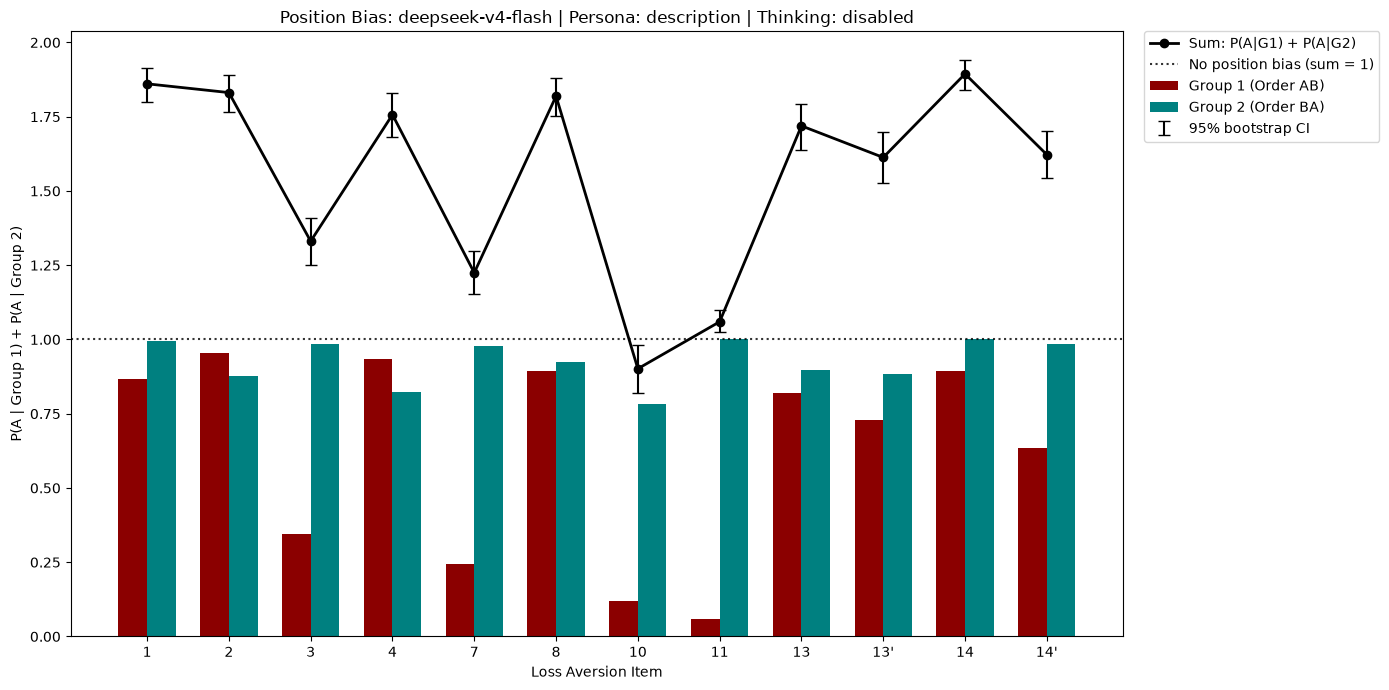

--------------------------------------------------------------------------------
Overall position bias across all items: 0.553, P(A) = 0.776
95% CI: [0.528, 0.577]
Significant: True
--------------------------------------------------------------------------------


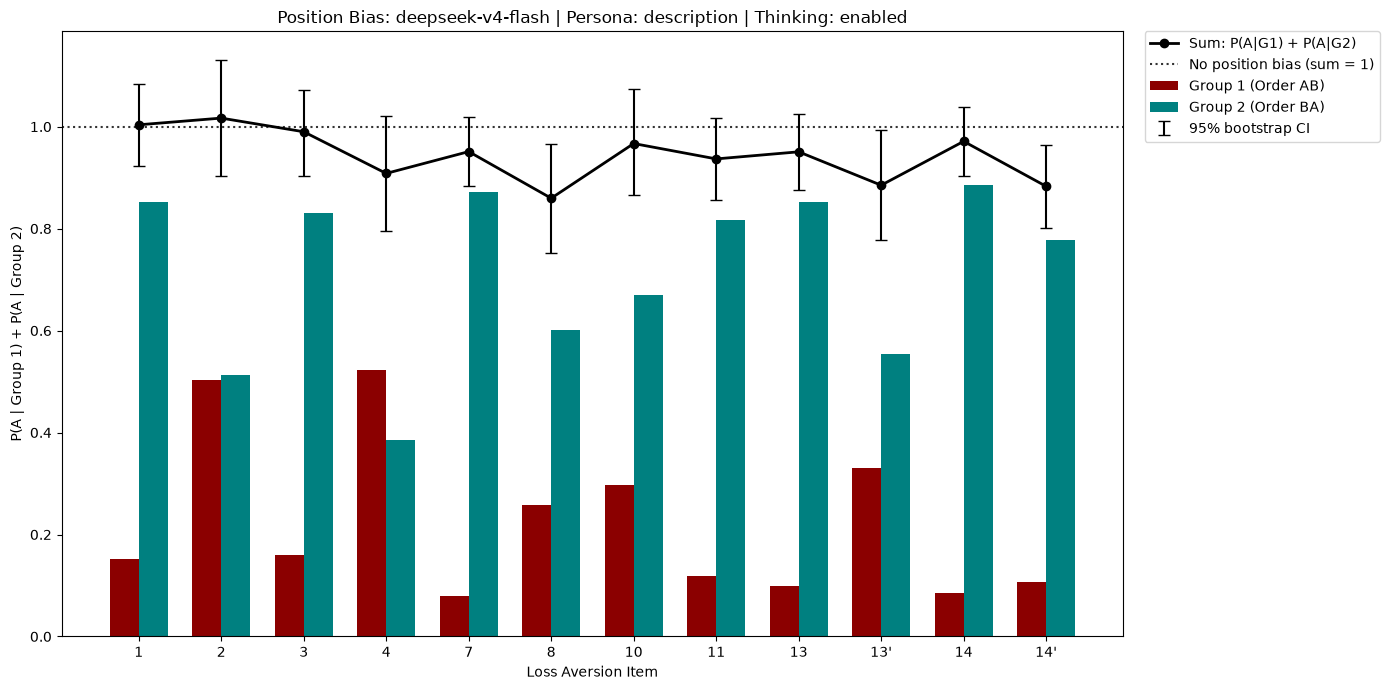

--------------------------------------------------------------------------------
Overall position bias across all items: -0.056, P(A) = 0.472
95% CI: [-0.122, 0.008]
Significant: False
--------------------------------------------------------------------------------


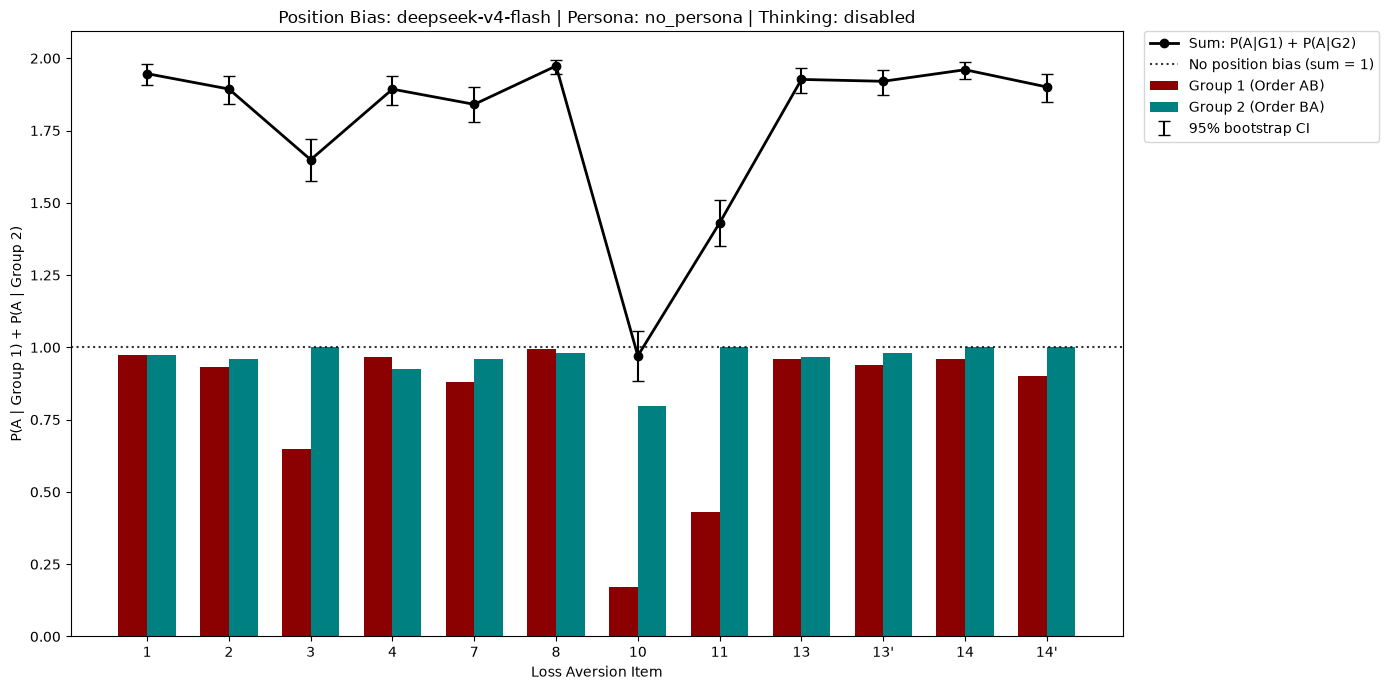

--------------------------------------------------------------------------------
Overall position bias across all items: 0.775, P(A) = 0.888
95% CI: [0.759, 0.791]
Significant: True
--------------------------------------------------------------------------------


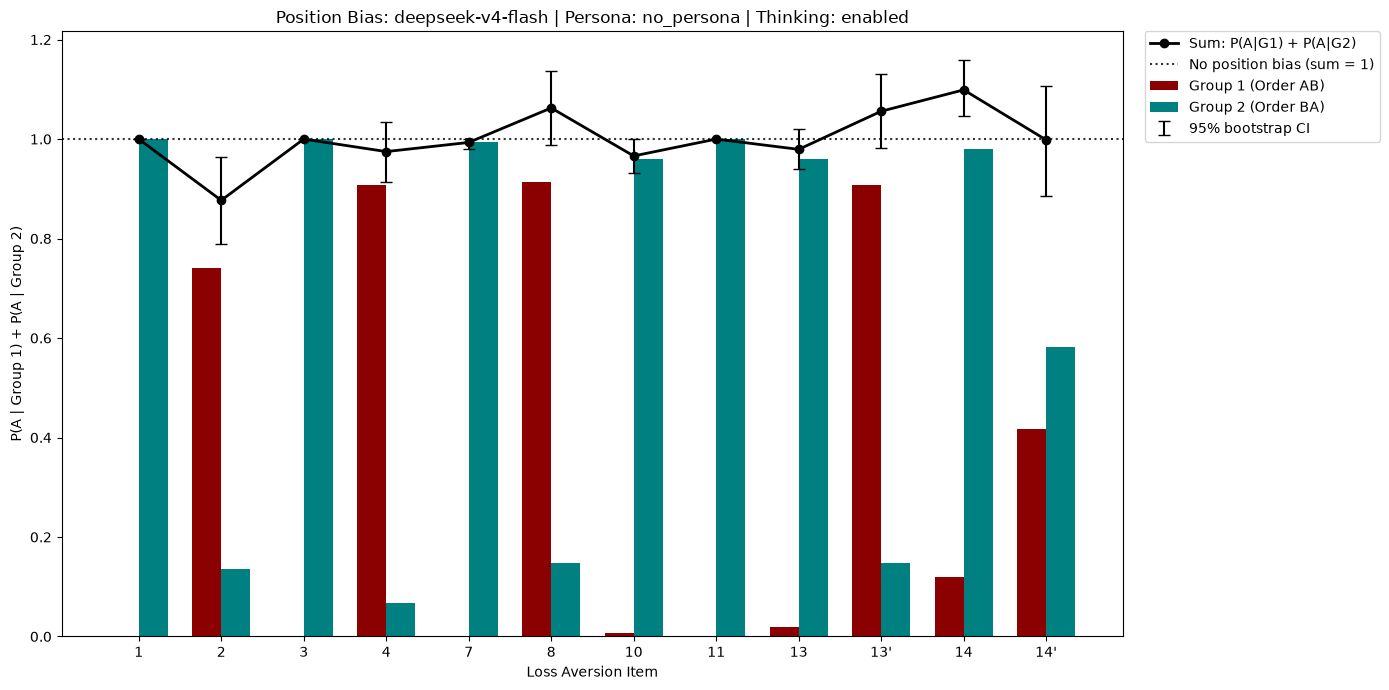

--------------------------------------------------------------------------------
Overall position bias across all items: 0.001, P(A) = 0.500
95% CI: [-0.017, 0.018]
Significant: False
--------------------------------------------------------------------------------


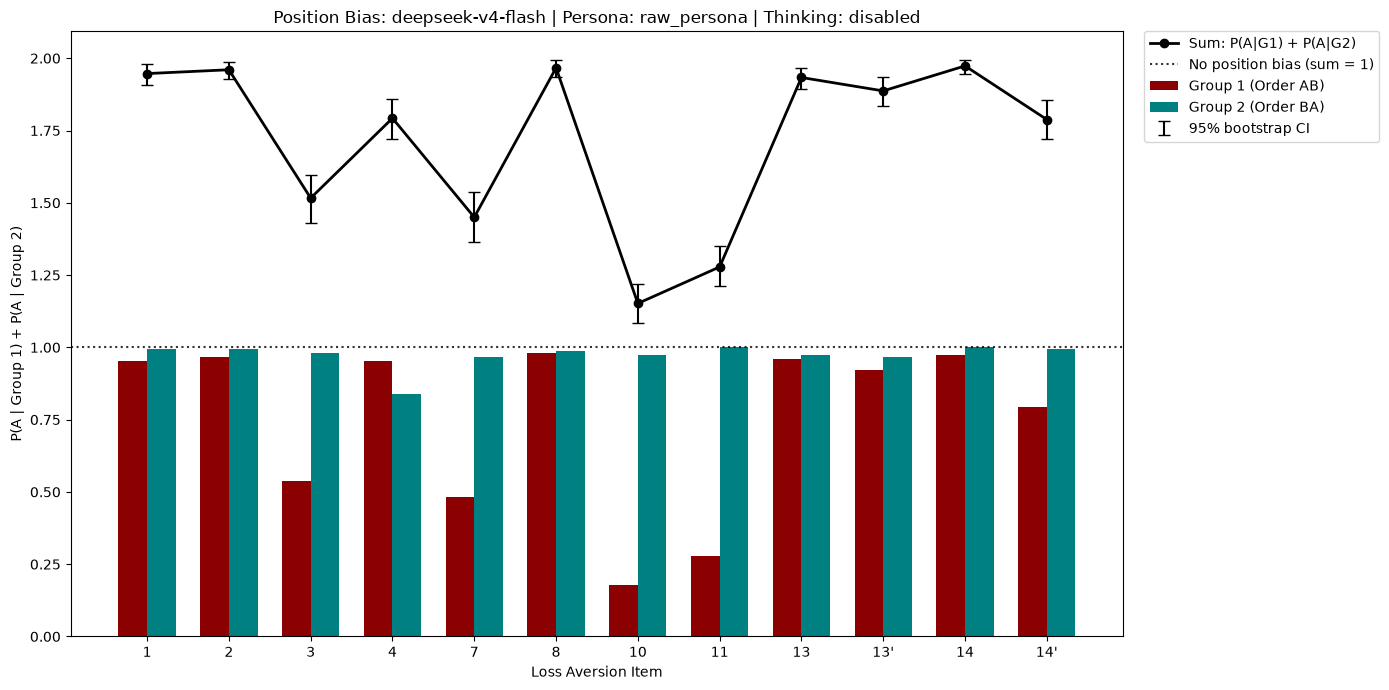

--------------------------------------------------------------------------------
Overall position bias across all items: 0.720, P(A) = 0.860
95% CI: [0.702, 0.738]
Significant: True
--------------------------------------------------------------------------------


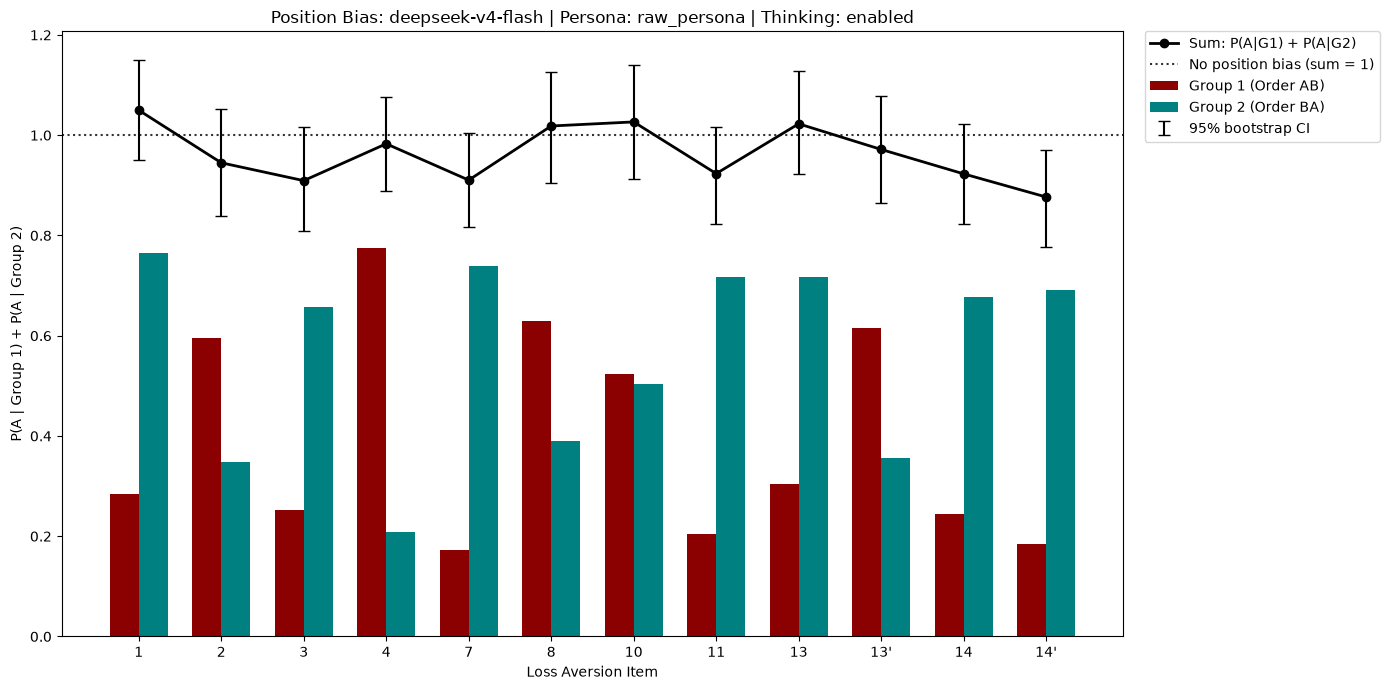

--------------------------------------------------------------------------------
Overall position bias across all items: -0.037, P(A) = 0.482
95% CI: [-0.106, 0.033]
Significant: False
--------------------------------------------------------------------------------


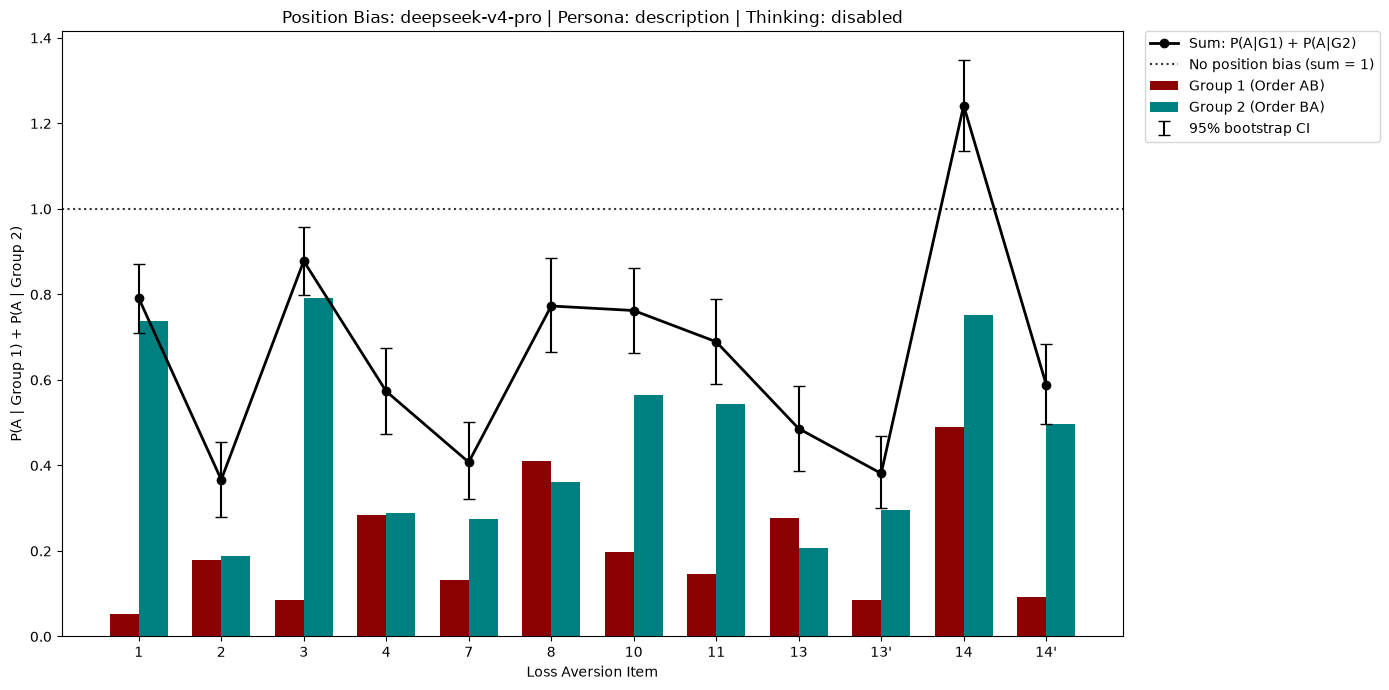

--------------------------------------------------------------------------------
Overall position bias across all items: -0.338, P(A) = 0.331
95% CI: [-0.372, -0.306]
Significant: True
--------------------------------------------------------------------------------


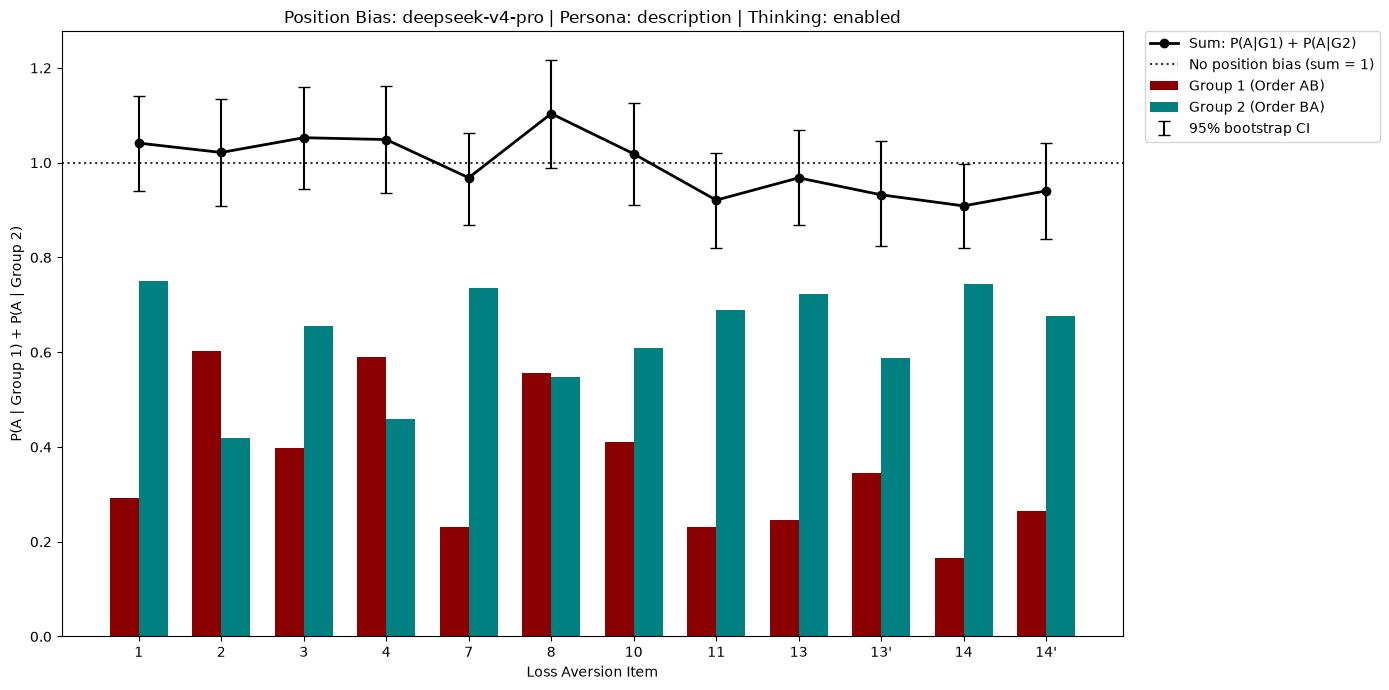

--------------------------------------------------------------------------------
Overall position bias across all items: -0.006, P(A) = 0.497
95% CI: [-0.085, 0.072]
Significant: False
--------------------------------------------------------------------------------


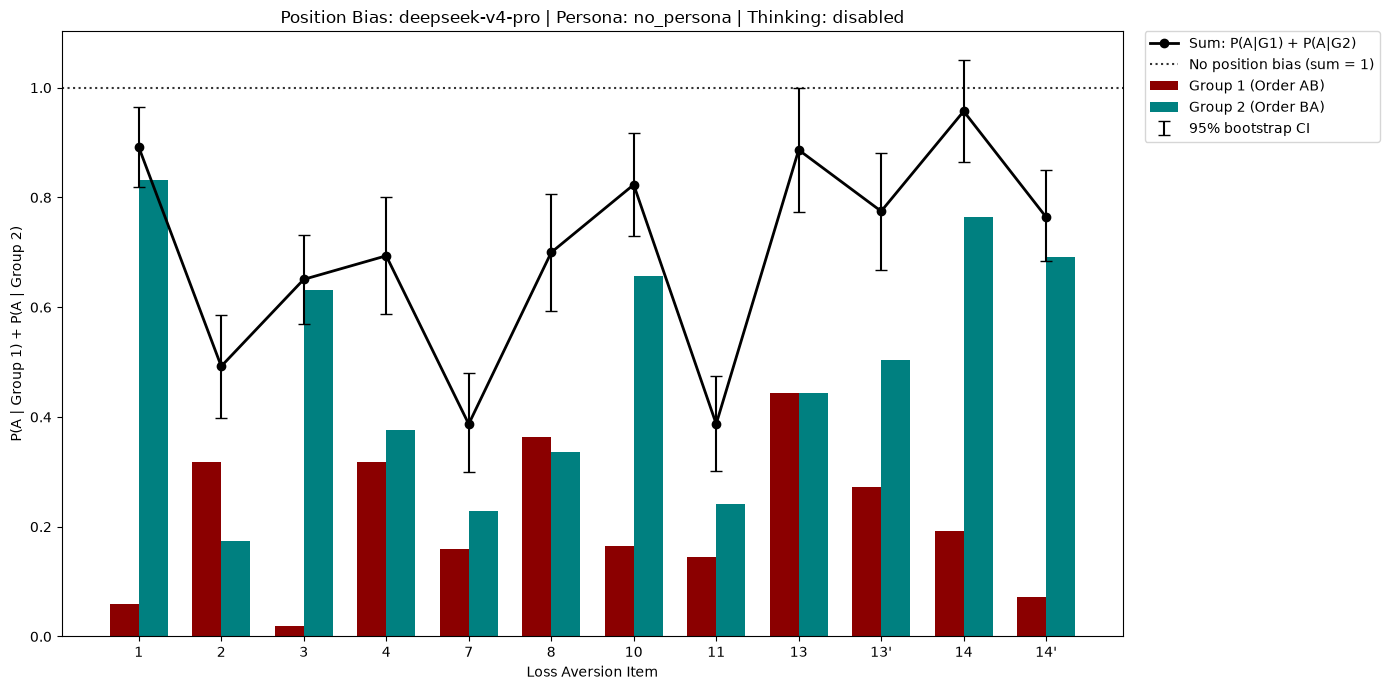

--------------------------------------------------------------------------------
Overall position bias across all items: -0.299, P(A) = 0.350
95% CI: [-0.327, -0.272]
Significant: True
--------------------------------------------------------------------------------


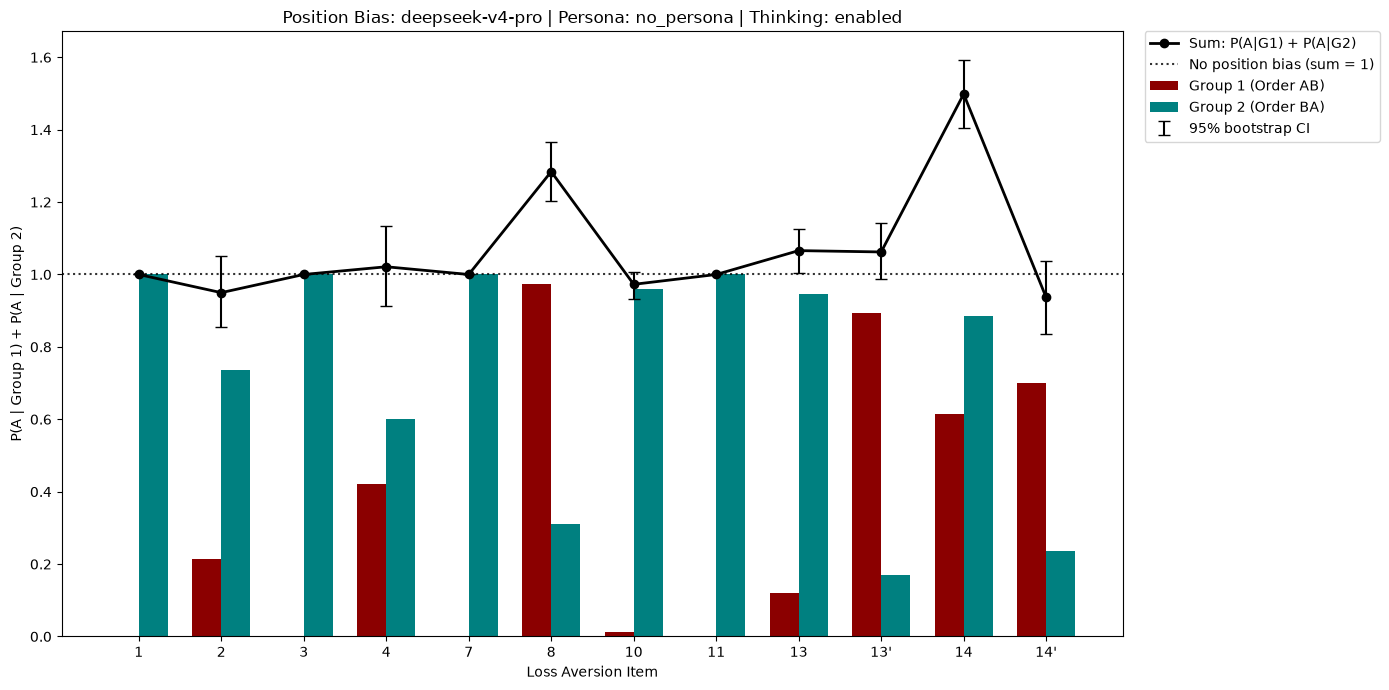

--------------------------------------------------------------------------------
Overall position bias across all items: 0.066, P(A) = 0.533
95% CI: [0.045, 0.086]
Significant: True
--------------------------------------------------------------------------------


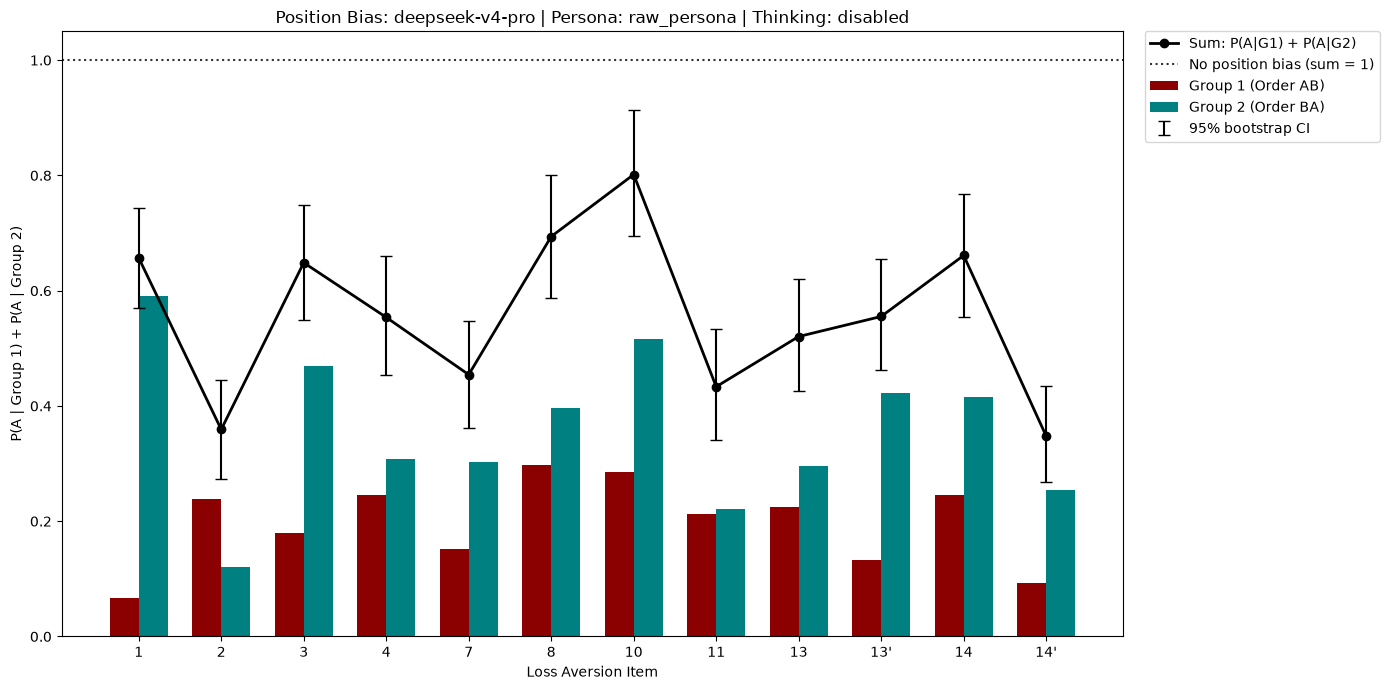

--------------------------------------------------------------------------------
Overall position bias across all items: -0.443, P(A) = 0.279
95% CI: [-0.471, -0.414]
Significant: True
--------------------------------------------------------------------------------


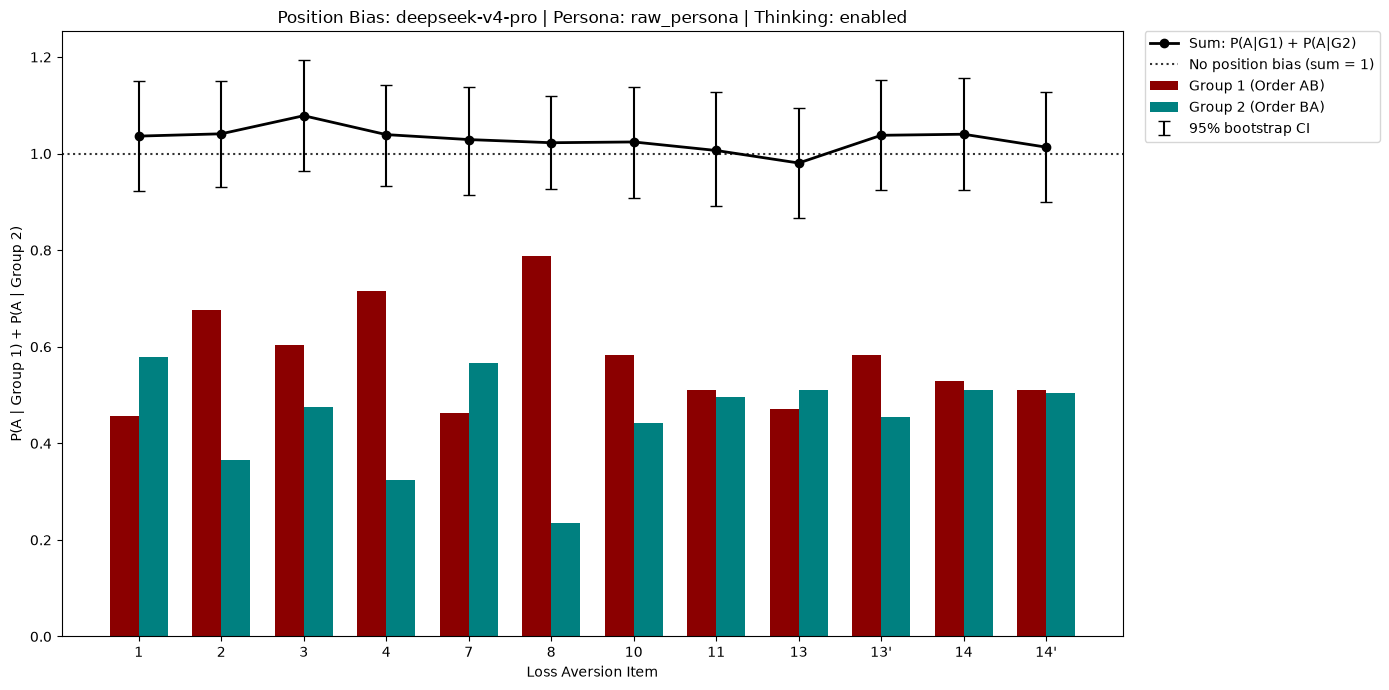

--------------------------------------------------------------------------------
Overall position bias across all items: 0.029, P(A) = 0.515
95% CI: [-0.058, 0.117]
Significant: False
--------------------------------------------------------------------------------


In [7]:
position_bias_rows = []
for (llm, persona, thinking), condition_df in df.groupby(["llm", "persona", "thinking"]):

    item_summary, summary, bootstrap_statistics = test_position_bias(condition_df)
    # create for postion bias df
    position_bias_rows.append({
        "llm": llm,
        "persona": persona,
        "thinking": thinking,
        "position_bias": summary["position_bias"].iloc[0],
        "position_bias_p_A": summary["position_bias_p_A"].iloc[0],
        "position_bias_lower_95CI": summary["lower_95CI"].iloc[0],
        "position_bias_upper_95CI": summary["upper_95CI"].iloc[0],
        "position_bias_significant": summary["significant_first_position_bias"].iloc[0]
    })
    
    title = (
        f"Position Bias: {llm} | "
        f"Persona: {persona} | "
        f"Thinking: {thinking}"
    )

    plot_position_bias(
        item_summary=item_summary,
        title=title
    )
    print("-" * 80)
    print(f"Overall position bias across all items: {summary['position_bias'].iloc[0]:.3f}, P(A) = {summary['position_bias_p_A'].iloc[0]:.3f}")
    print(f"95% CI: [{summary['lower_95CI'].iloc[0]:.3f}, {summary['upper_95CI'].iloc[0]:.3f}]")
    print(f"Significant: {summary['significant_first_position_bias'].iloc[0]}")
    print("-" * 80)
position_bias_summary = pd.DataFrame(position_bias_rows)

In [8]:
# Invert the responses for group 2
cols = [c for c in df.columns if c.startswith("Loss_Aversion_")]
mask = df["experiment_group"] == 2
swap = {"A": "B", "B": "A"}
df.loc[mask, cols] = df.loc[mask, cols].replace(swap)
print(f"Total missing values across df: {df.isna().sum().sum()}")

Total missing values across df: 0


Read data from [Ruggeri et al., (2020)](https://osf.io/esxc4/overview) for human comparison and remap the items to match the original prospect theory items (and by extension my order)

In [9]:
long_data = pd.read_csv("../prospect_theory_meta_analysis_data/proportions_by_country.csv")
prop_df = pd.read_csv("../prospect_theory_meta_analysis_data/Meta analysis proportions.csv")
original_pt_proportions_df = pd.read_csv("../prospect_theory_meta_analysis_data/original_proportions.csv")

# recode to match with original paper item order
# 13 == 12 which is corrupted in my thesis
long_data = long_data[~long_data["Item"].isin([7, 8, 9, 10, 13])].copy()
item_mapping = {
    1: "1",
    2: "2",
    3: "3",
    4: "4",
    5: "7",
    6: "8",
    11: "10",
    12: "11",
    14: "13",
    15: "13'",
    16: "14",
    17: "14'"
}
long_data["Item"] = long_data["Item"].map(item_mapping)
long_data.loc[long_data["Succesful Replication"].isna(),"Succesful Replication"] = "NA"

prop_df = prop_df[~prop_df["Item"].isin([7, 8, 9, 10, 13])].copy()
prop_df["Item"] = prop_df["Item"].map(item_mapping)

original_pt_proportions_df = original_pt_proportions_df[~original_pt_proportions_df["Item"].isin([7, 8, 9, 10, 13])].copy()
original_pt_proportions_df["Item"] = original_pt_proportions_df["Item"].map(item_mapping)

calculate A response proportion and data transformation to align df for plotting

In [10]:
excluded = {"Loss_Aversion_5", "Loss_Aversion_6", "Loss_Aversion_9", "Loss_Aversion_12"}
loss_cols = [col for col in df.columns if col.startswith("Loss_Aversion") and col not in excluded]

# Long format
long_df = df.melt(
    id_vars=["llm", "persona", "thinking"],
    value_vars=loss_cols,
    var_name="question",
    value_name="answer"
)

results = []
for (llm, persona, thinking, question), group in long_df.groupby(["llm", "persona", "thinking", "question"]):

    n_A = (group["answer"] == "A").sum()
    n = len(group)
    pct_A = n_A / n

    results.append({
        "llm": llm,
        "persona": persona,
        "thinking": thinking,
        "question": question,
        "n": n,
        "n_A": n_A,
        "A_proportion": pct_A,
    })

results = pd.DataFrame(results)
results = results.sort_values(["llm", "persona", "thinking", "question"])
llm_item_mapping = {
    "Loss_Aversion_1": "1",
    "Loss_Aversion_2": "2",
    "Loss_Aversion_3": "3",
    "Loss_Aversion_4": "4",
    "Loss_Aversion_7": "7",
    "Loss_Aversion_8": "8",
    "Loss_Aversion_10": "10",
    "Loss_Aversion_11": "11",
    "Loss_Aversion_13": "13",
    "Loss_Aversion_13_inverse": "13'",
    "Loss_Aversion_14": "14",
    "Loss_Aversion_14_inverse": "14'"
}
results["Item"] = results["question"].map(llm_item_mapping)

item_order = list(llm_item_mapping.values())
item_to_x = {item: i for i, item in enumerate(item_order)}

original_pt_proportions_df["x_pos"] = (original_pt_proportions_df["Item"].map(item_to_x))
prop_df["x_pos"] = (prop_df["Item"].map(item_to_x))
long_data["x_pos"] = (long_data["Item"].map(item_to_x))
results["x_pos"] = (results["Item"].map(item_to_x))

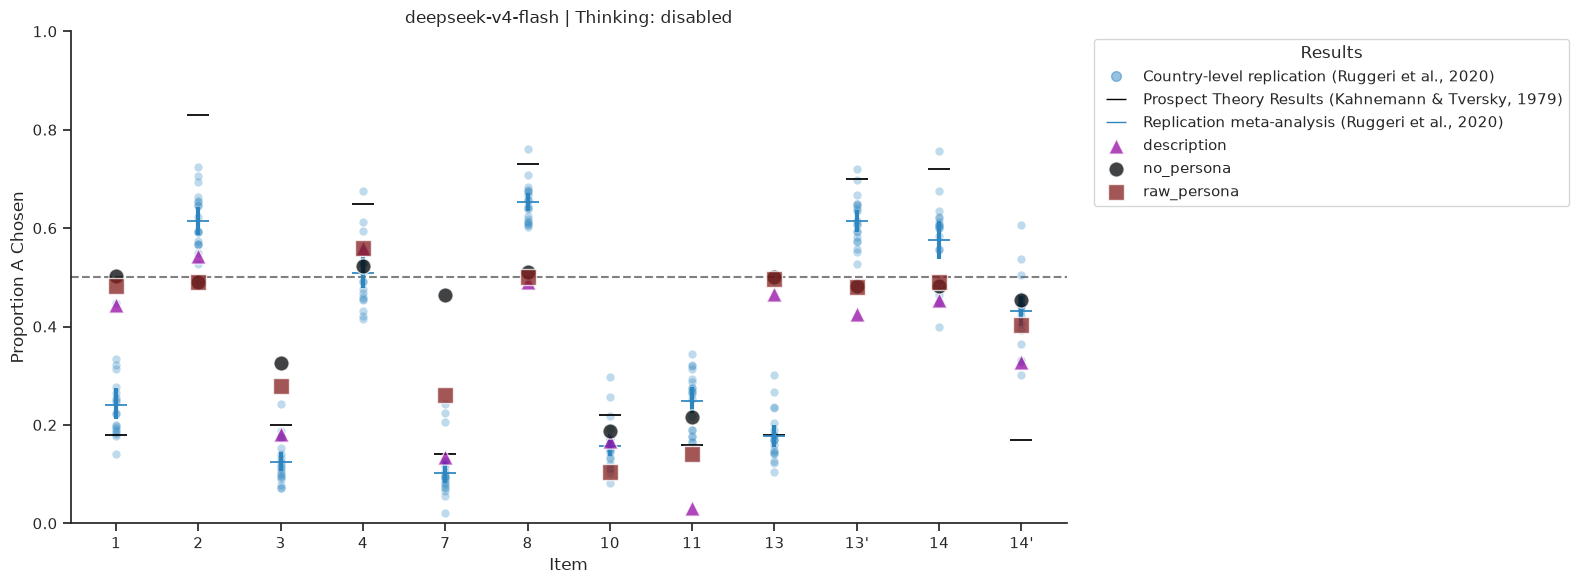

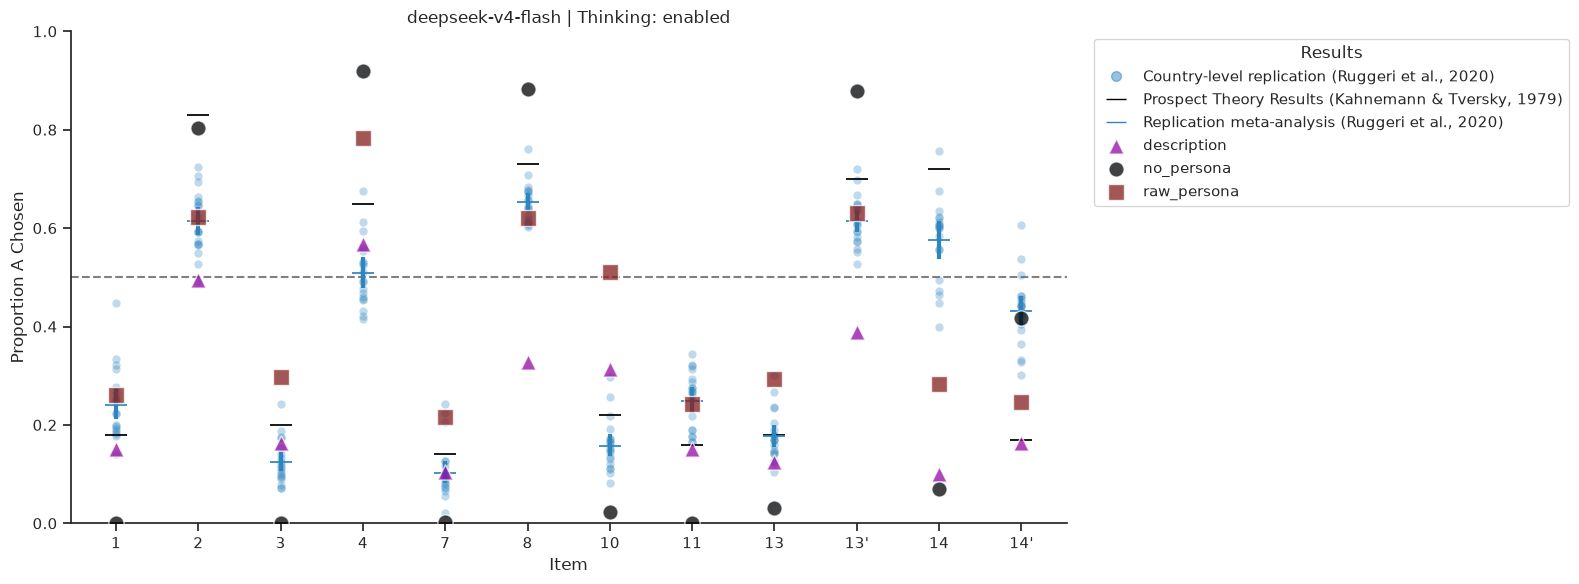

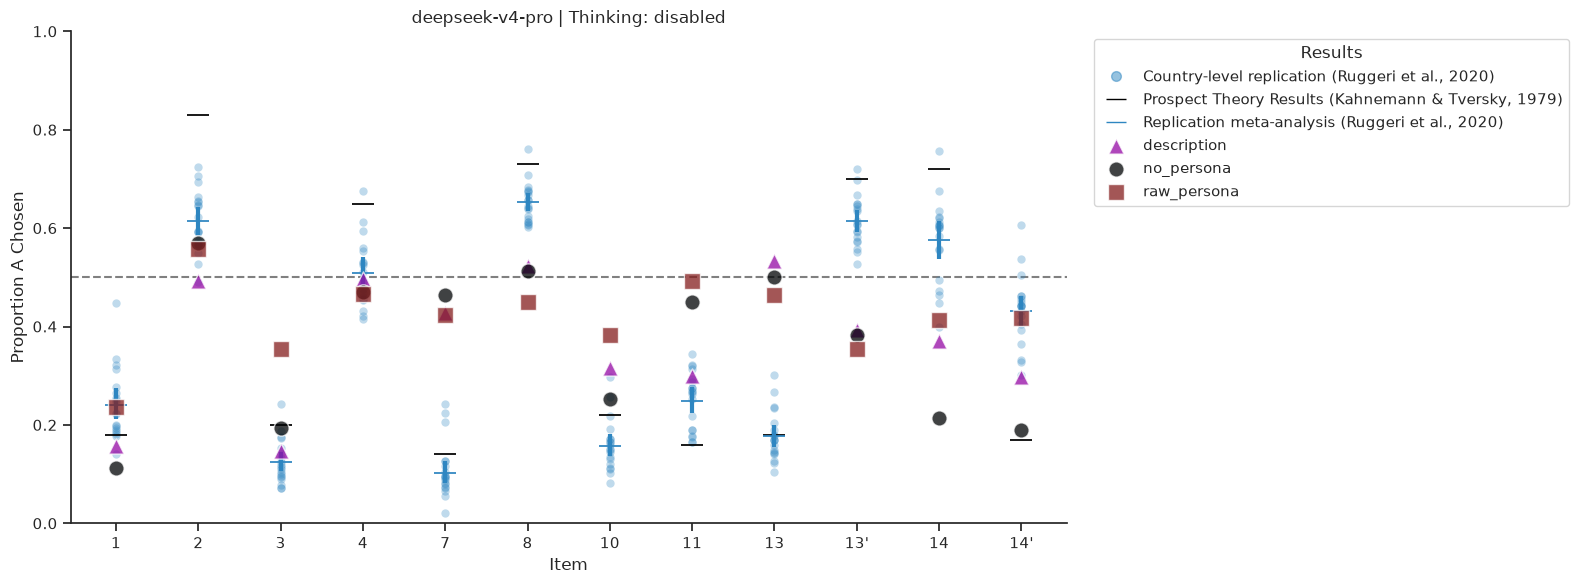

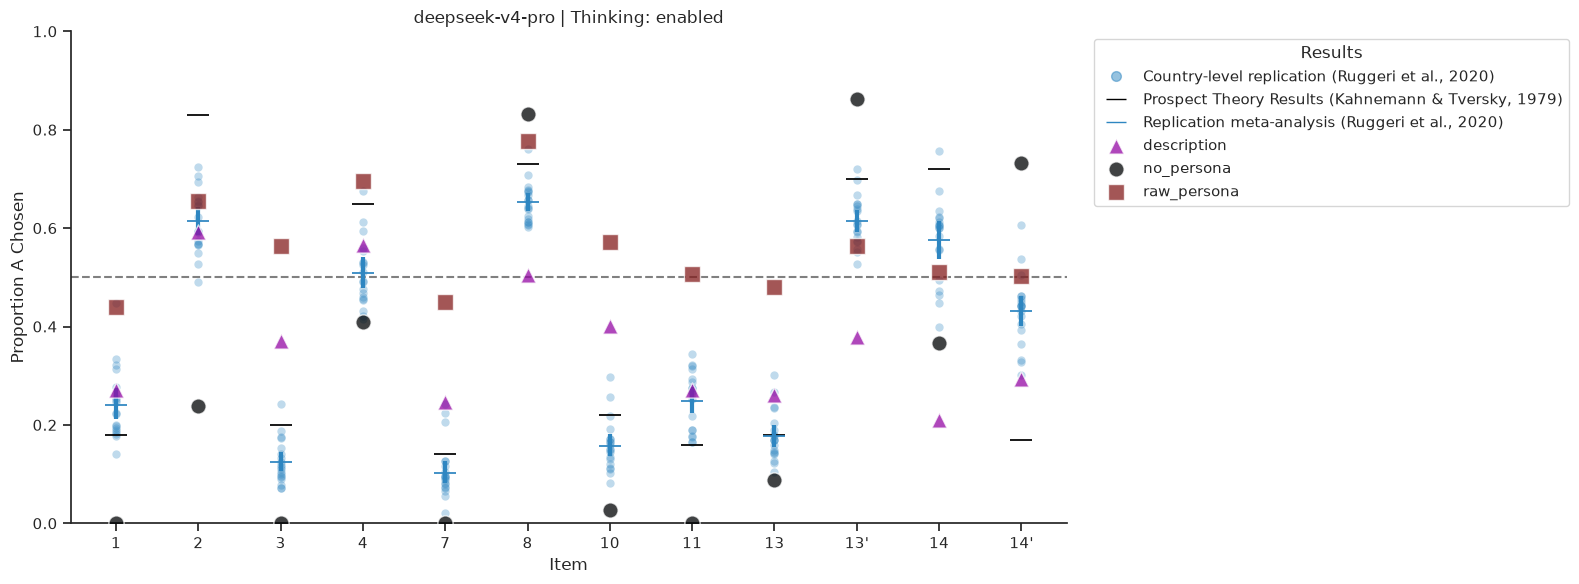

In [11]:
# also plot 5, 6 and 9?
sns.set_theme(font_scale=1, style="ticks")

# Markers for the three persona conditions
persona_markers = {
    "no_persona": "o",
    "raw_persona": "s",
    "description": "^"
}

# Colors for the three persona conditions
persona_colors = {
    "no_persona": "#000304",
    "raw_persona": "#841E1E",
    "description": "#9409a4"
}


for (llm, thinking), group_df in results.groupby(["llm", "thinking"]):

    fig, ax = plt.subplots(figsize=(16, 6))


    # COUNTRY-LEVEL REPLICATION DATA FROM Ruggeri et al., 2020
    sns.scatterplot(
        x="x_pos",
        y="Proportion",
        data=long_data,
        # hue="Succesful Replication",
        # hue_order=["Yes", "No", "NA"],
        # style="Succesful Replication",
        linewidth=0,
        alpha=0.3,
        color="#2e86c1",
        markers="o",
        ax=ax,
        zorder=1,
        legend=False
    )


    # ORIGINAL KAHNEMAN & TVERSKY
    sns.scatterplot(
        data=original_pt_proportions_df,
        x="x_pos",
        y="Proportion",
        marker="_",
        s=250,
        color="black",
        ax=ax,
        zorder=2,
        legend=False
    )


    # REPLICATION META-ANALYSIS
    sns.scatterplot(
        data=prop_df,
        x="x_pos",
        y="prop",
        # hue="Succesful Replication",
        # hue_order=["Yes", "No", "NA"],
        marker="_",
        s=250,
        color="#2e86c1",
        ax=ax,
        zorder=4,
        legend=False
    )

    # META-ANALYSIS ERROR BARS
    for _, row in prop_df.dropna(subset=["x_pos"]).iterrows():

        x = int(row["x_pos"])

        lower_error = row["prop"] - row["lb"]
        upper_error = row["ub"] - row["prop"]

        ax.errorbar(
            x,
            row["prop"],
            yerr=[
                [lower_error],
                [upper_error]
            ],
            linestyle="",
            linewidth=3,
            color="#2e86c1",
            capsize=0,
            zorder=3
        )


    # LLM REPLICATION RESULTS
    for persona, persona_df in group_df.groupby("persona"):

        sns.scatterplot(
            data=persona_df,
            x="x_pos",
            y="A_proportion",
            marker=persona_markers.get(persona, "o"),
            s=120,
            color=persona_colors.get(persona, "black"),
            edgecolor="white",
            linewidth=1,
            ax=ax,
            zorder=5,
            label=persona,
            alpha=.75
        )


    # INDIFFERENCE LINE
    ax.axhline(
        y=0.5,
        linestyle="--",
        color="grey",
        zorder=0
    )


    ax.set_xticks(range(len(item_order)))
    ax.set_xticklabels(item_order)
    ax.set_xlabel("Item")
    ax.set_ylabel("Proportion A Chosen")
    ax.set_ylim(0, 1)
    ax.set_title(f"{llm} | Thinking: {thinking}")
    handles, labels = ax.get_legend_handles_labels()

    from matplotlib.lines import Line2D
    handles = [
        Line2D([], [], marker="o", color="#2e86c1",
               linestyle="none", markersize=7,
               alpha=0.5, label="Country-level replication (Ruggeri et al., 2020)"),

        Line2D([], [], marker="_", color="black",
               linestyle="none", markersize=14,
               label="Prospect Theory Results (Kahnemann & Tversky, 1979)"),

        Line2D([], [], marker="_", color="#2e86c1",
               linestyle="none", markersize=14,
               label="Replication meta-analysis (Ruggeri et al., 2020)")
    ] + handles

    labels = [
        "Country-level replication (Ruggeri et al., 2020)",
        "Prospect Theory Results (Kahnemann & Tversky, 1979)",
        "Replication meta-analysis (Ruggeri et al., 2020)"
    ] + labels

    ax.legend(
        handles=handles,
        labels=labels,
        title="Results",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    sns.despine()
    plt.tight_layout()

In [12]:
prospect_theory_raw_data = pd.read_csv("../prospect_theory_meta_analysis_data/pt_replication_modified_exclusions_data.csv", index_col=0) # 1 == A response
prospect_theory_raw_data["Country"].unique()

<StringArray>
[      'Bulgaria',      'Hong Kong', 'Mainland China',        'Denmark',
        'Belgium',      'Australia',        'Ireland',             'UK',
            'USA',        'Austria',        'Germany',        'Hungary',
          'Italy',         'Norway',         'Serbia',       'Slovenia',
          'Chile',          'Spain',         'Sweden']
Length: 19, dtype: str

In [13]:
prospect_theory_raw_data = pd.read_csv("../prospect_theory_meta_analysis_data/pt_replication_modified_exclusions_data.csv", index_col=0) # 1 == A response

# Recode item numbers to match the original paper's (and this thesis) item order
item_mapping = {
    "1": "1",
    "2": "2",
    "3": "3",
    "4": "4",
    "5": "7",
    "6": "8",
    "11": "10",
    "12": "11",
    "14": "13",
    "15": "13'",
    "16": "14",
    "17": "14'"
}

prospect_theory_raw_data = (
    prospect_theory_raw_data
    .loc[:, prospect_theory_raw_data.columns.astype(str).isin(item_mapping.keys())]
    .rename(columns=item_mapping)
)

In [25]:
N_BOOTSTRAPS = 10_000
rng = np.random.default_rng(1)

bootstrap_results = []

# Human data
human_values = prospect_theory_raw_data.to_numpy(dtype=float)
n_humans = human_values.shape[0]
human_items = list(prospect_theory_raw_data.columns)

# LLM data
loss_cols = [col for col in df.columns if col.startswith("Loss_Aversion")]

for (llm, persona, thinking), condition in df.groupby( ["llm", "persona", "thinking"]):

    llm_values = condition[loss_cols].to_numpy()
    n_llm = llm_values.shape[0]

    for i in range(N_BOOTSTRAPS):

        # Resample LLM participants
        llm_idx = rng.integers(0, n_llm, size=n_llm)
        llm_sample = llm_values[llm_idx]
        p_llm = (llm_sample == "A").mean(axis=0)


        # Resample human participants independently
        human_idx = rng.integers(0, n_humans, size=n_humans)
        human_sample = human_values[human_idx]
        p_human = np.nanmean(human_sample, axis=0)

        # Directly calculate abs(LLM - human) difference
        err_llm = np.abs(p_llm - p_human)
        # Random baseline: P(A) = 0.5
        p_random = 0.5
        err_random = np.abs(p_random - p_human)

        # calculate the improvement of LLM over random baseline
        improvements = err_random - err_llm

        # Store bootstrap results
        for question, a_llm, a_human, improvement in zip(loss_cols, p_llm, p_human, improvements):

            question_clean = (question.replace("Loss_Aversion_", "").replace("_inverse", "'"))

            bootstrap_results.append({
                "llm": llm,
                "persona": persona,
                "thinking": thinking,
                "question": question_clean,
                "bootstrap": i,
                "improvement_over_random": improvement,
                "A_p_llm": a_llm,
                "A_p_human": a_human
            })

bootstrap_results = pd.DataFrame(bootstrap_results)

# Observed human proportion
human_obs = (
    prospect_theory_raw_data
    .mean()
    .rename("p_human")
    .reset_index()
    .rename(columns={"index": "question"})
)

# Observed LLM proportion
llm_obs = (
    df.melt(
        id_vars=["llm", "persona", "thinking"],
        value_vars=loss_cols,
        var_name="question",
        value_name="answer"
    )
    .assign(p_llm=lambda x: (x["answer"] == "A").astype(float))
    .groupby(["llm", "persona", "thinking", "question"])["p_llm"]
    .mean()
    .reset_index()
)

llm_obs["question"] = (
    llm_obs["question"]
    .str.replace("Loss_Aversion_", "", regex=False)
    .str.replace("_inverse", "'", regex=False)
)

bootstrap_summary = llm_obs.merge(human_obs, on="question")

# Point estimate of improvement over random baseline
bootstrap_summary["improvement_over_random"] = (
    (0.5 - bootstrap_summary["p_human"]).abs()
    - (bootstrap_summary["p_llm"] - bootstrap_summary["p_human"]).abs()
)
# Bootstrap 95% CI
# Bonferroni correction for multiple comparisons
n_tests = bootstrap_summary.shape[0]
alpha = 0.05 / n_tests
improvement_over_random_ci = (
    bootstrap_results
    .groupby(["llm", "persona", "thinking", "question"])["improvement_over_random"]
    .agg(
        lower_95CI=lambda x: x.quantile(alpha / 2),
        upper_95CI=lambda x: x.quantile(1 - alpha / 2)
    )
    .reset_index()
)

bootstrap_summary = bootstrap_summary.merge(improvement_over_random_ci,on=["llm", "persona", "thinking", "question"])
bootstrap_summary

,llm,persona,thinking,question,p_llm,p_human,improvement_over_random,lower_95CI,upper_95CI
0,deepseek-v4-flash,description,disabled,1,0.442953,0.254758,0.057047,-0.057047,0.148537
1,deepseek-v4-flash,description,disabled,10,0.167785,0.160566,0.332215,0.248322,0.353422
2,deepseek-v4-flash,description,disabled,11,0.030201,0.253782,0.022637,-0.034817,0.082004
3,deepseek-v4-flash,description,disabled,13,0.466443,0.177852,0.033557,-0.072242,0.144295
4,deepseek-v4-flash,description,disabled,13',0.426174,0.615745,-0.073826,-0.175383,0.024376
...,...,...,...,...,...,...,...,...,...
139,deepseek-v4-pro,raw_persona,enabled,2,0.655405,0.617862,0.080319,-0.024057,0.138514
140,deepseek-v4-pro,raw_persona,enabled,3,0.564189,0.128355,-0.064189,-0.159676,0.037162
141,deepseek-v4-pro,raw_persona,enabled,4,0.695946,0.511713,-0.172520,-0.268078,-0.065561
142,deepseek-v4-pro,raw_persona,enabled,7,0.449324,0.108590,0.050676,-0.050676,0.147054


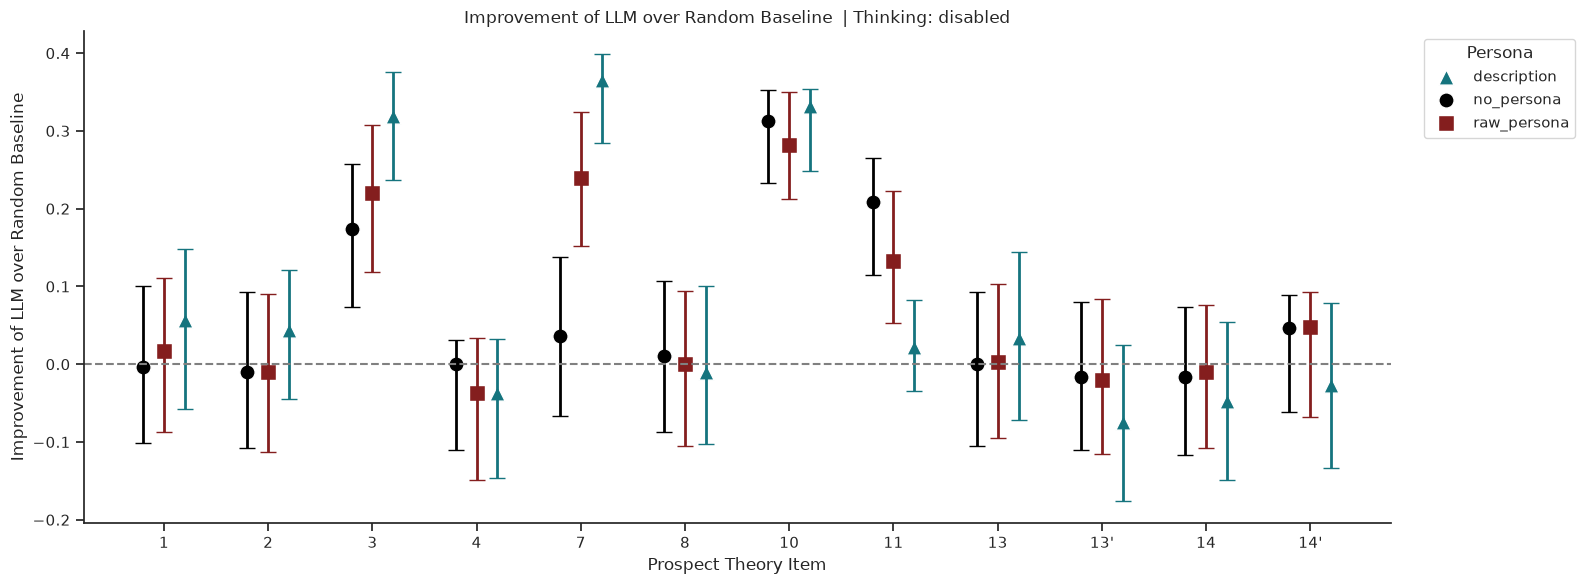

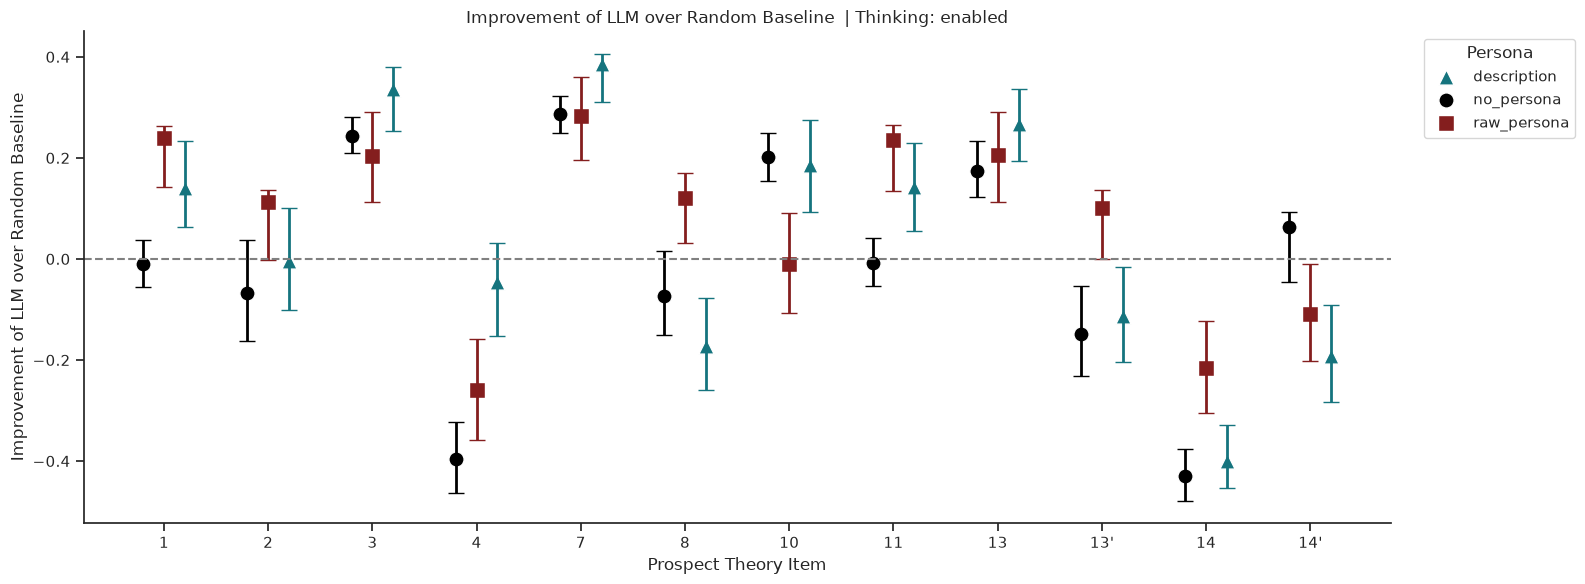

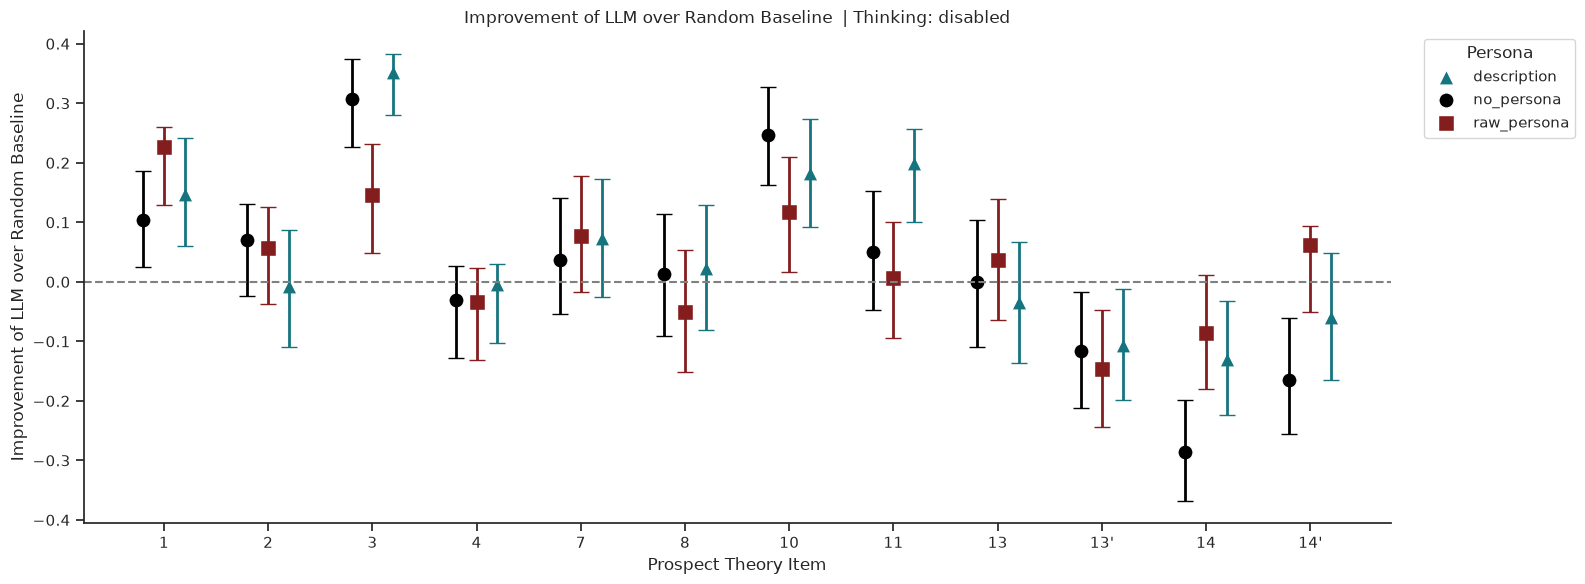

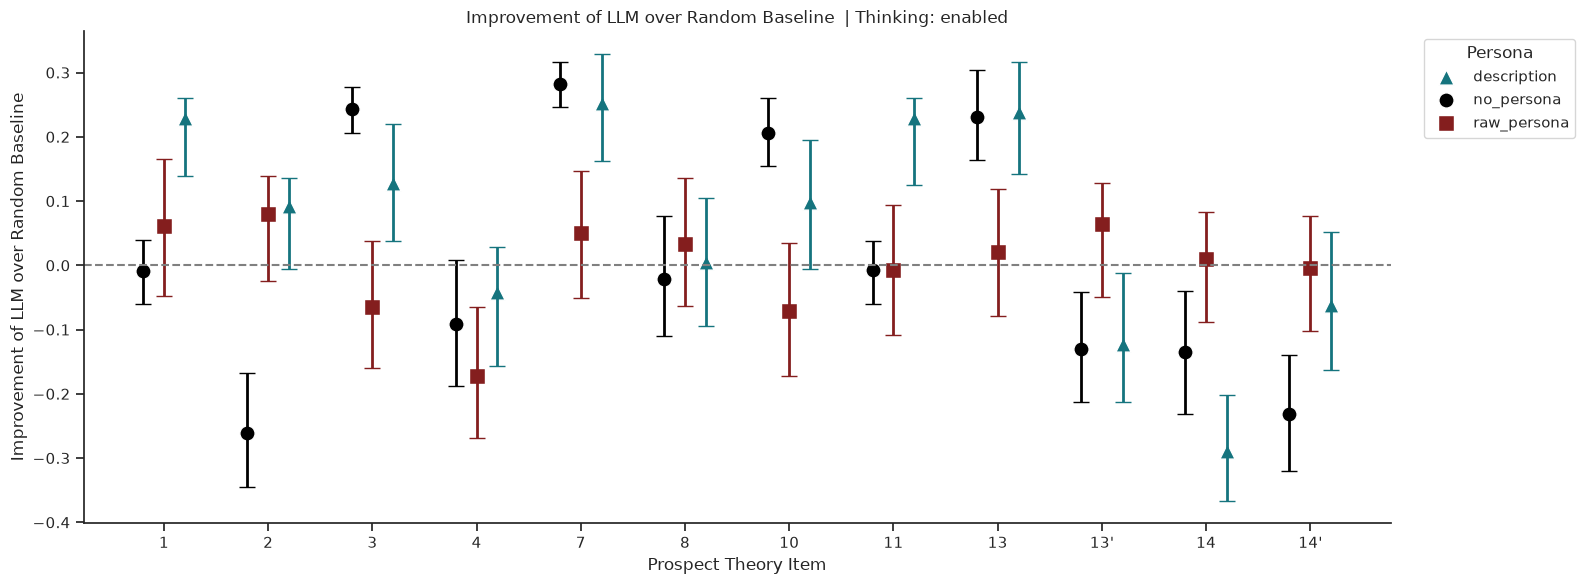

In [26]:
sns.set_theme(font_scale=1, style="ticks")
# Markers for the three persona conditions
persona_markers = {
    "no_persona": "o",
    "raw_persona": "s",
    "description": "^",
}

# Colors for the three persona conditions
persona_colors = {
    "no_persona": "#000000",
    "raw_persona": "#841E1E",
    "description": "#15747e"
}
# Horizontal offsets so the three personas appear side-by-side
persona_offsets = {
    "no_persona": -0.20,
    "raw_persona": 0.00,
    "description": 0.20
}

for (llm, thinking), group_df in bootstrap_summary.groupby(["llm", "thinking"]):

    fig, ax = plt.subplots(figsize=(16, 6))

    for persona, persona_df in group_df.groupby("persona"):

        # Make sure items are in the desired order
        persona_df = persona_df.copy()
        persona_df["x_pos"] = persona_df["question"].map(item_to_x)
        persona_df["x_pos"] += persona_offsets.get(persona, 0)
        persona_df = persona_df.sort_values("x_pos")
        color = persona_colors[persona]
        marker = persona_markers[persona]

        # Point estimate
        ax.scatter(
            persona_df["x_pos"],
            persona_df["improvement_over_random"],
            marker=marker,
            s=120,
            color=color,
            edgecolor="white",
            linewidth=1,
            label=persona,
        )

        # 95% CI
        ax.errorbar(
            persona_df["x_pos"],
            persona_df["improvement_over_random"],
            yerr=[
                persona_df["improvement_over_random"] - persona_df["lower_95CI"],
                persona_df["upper_95CI"] - persona_df["improvement_over_random"]
            ],
            fmt="none",
            ecolor=color,
            elinewidth=2,
            capsize=6
        )

    ax.axhline(
        y=0,
        linestyle="--",
        color="grey",
        linewidth=1.5,
    )

    ax.set_xticks(range(len(item_order)))
    ax.set_xticklabels(item_order)
    ax.set_xlabel("Prospect Theory Item")
    ax.set_ylabel("Improvement of LLM over Random Baseline")
    ax.set_title(f"Improvement of LLM over Random Baseline  | Thinking: {thinking}")
    ax.legend(title="Persona", bbox_to_anchor=(1.02, 1), loc="upper left")
    sns.despine()
    plt.tight_layout()
    plt.savefig(f"plots/risk_aversion_behavioral_alignment/llm_human_delta_{llm}_{thinking}.png")

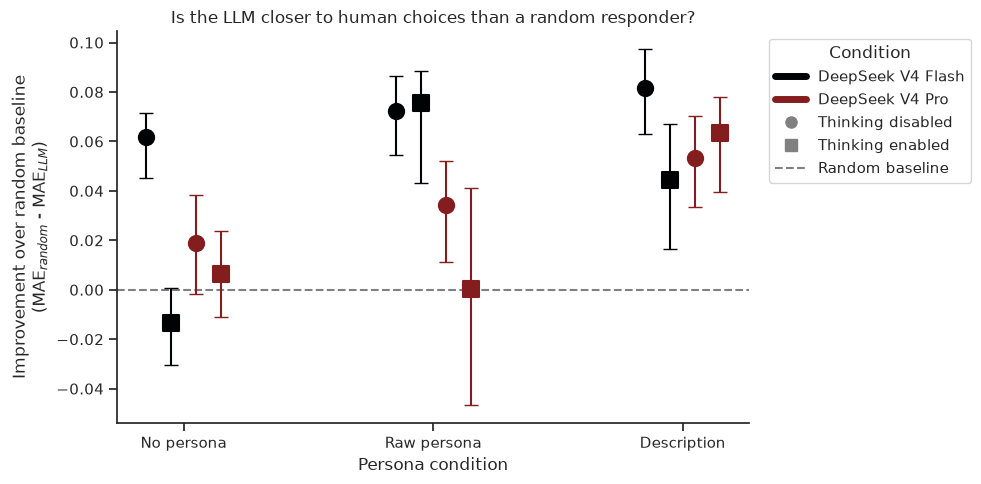

In [ ]:
conditions = ["llm", "persona", "thinking"]

# Mean improvement across all items for each condition
agg_observed = (
    bootstrap_summary
    .groupby(conditions)["improvement_over_random"]
    .mean()
    .reset_index(name="improvement")
)

# Same aggregate inside every bootstrap replicate
agg_bootstrap = (
    bootstrap_results
    .groupby(conditions + ["bootstrap"])["improvement_over_random"]
    .mean()
    .reset_index(name="improvement")
)

# Bonferroni adjustment for multiple comparisons
n_tests = agg_observed.shape[0]
alpha = 0.05 / n_tests

agg_ci = (
    agg_bootstrap
    .groupby(conditions)["improvement"]
    .agg(
        lower_CI=lambda x: x.quantile(alpha / 2),
        upper_CI=lambda x: x.quantile(1 - alpha / 2)
    )
    .reset_index()
)

improvement_summary = agg_observed.merge(agg_ci, on=conditions)

sns.set_theme(font_scale=1, style="ticks")

persona_order = ["no_persona", "raw_persona", "description"]
persona_labels = {
    "no_persona": "No persona",
    "raw_persona": "Raw persona",
    "description": "Description"
}
persona_to_x = {p: i for i, p in enumerate(persona_order)}

llm_colors = {"deepseek-v4-flash": "#000304", "deepseek-v4-pro": "#841E1E"}
llm_labels = {"deepseek-v4-flash": "DeepSeek V4 Flash", "deepseek-v4-pro": "DeepSeek V4 Pro"}
thinking_markers = {"disabled": "o", "enabled": "s"}
thinking_labels = {"disabled": "Thinking disabled", "enabled": "Thinking enabled"}
condition_offsets = {
    ("deepseek-v4-flash", "disabled"): -0.15,
    ("deepseek-v4-flash", "enabled"): -0.05,
    ("deepseek-v4-pro", "disabled"): 0.05,
    ("deepseek-v4-pro", "enabled"): 0.15,
}

plot_df = improvement_summary.copy()
plot_df["x_pos"] = plot_df.apply(
    lambda r: persona_to_x[r["persona"]] + condition_offsets[(r["llm"], r["thinking"])], axis=1
)

fig, ax = plt.subplots(figsize=(10, 5))

# Random baseline: improvement = 0
ax.axhline(0, linestyle="--", color="grey", linewidth=1.5, zorder=0)

for _, row in plot_df.iterrows():
    color = llm_colors[row["llm"]]
    ax.errorbar(
        row["x_pos"], row["improvement"],
        yerr=[[row["improvement"] - row["lower_CI"]], [row["upper_CI"] - row["improvement"]]],
        fmt="none", ecolor=color, elinewidth=1.5, capsize=5, zorder=2,
    )
    ax.scatter(
        row["x_pos"], row["improvement"],
        marker=thinking_markers[row["thinking"]], s=120,
        facecolor=color,
        edgecolor=color, linewidth=1.5, zorder=3,
    )

ax.set_xticks(range(len(persona_order)))
ax.set_xticklabels([persona_labels[p] for p in persona_order])
ax.set_xlabel("Persona condition")
ax.set_ylabel("Improvement over random baseline\n(MAE$_{random}$ - MAE$_{LLM}$)")
ax.set_title("Is the LLM closer to human choices than a random responder?")

legend_handles = [
    Line2D([], [], color=llm_colors[k], linewidth=5, label=v) for k, v in llm_labels.items()
] + [
    Line2D([], [], linestyle="none", marker=thinking_markers[k], markersize=8, color="grey", label=v)
    for k, v in thinking_labels.items()
] + [
    Line2D([], [], color="grey", linestyle="--", linewidth=1.5, label="Random baseline"),
]
ax.legend(handles=legend_handles, title="Condition", bbox_to_anchor=(1.02, 1), loc="upper left")

sns.despine()
plt.tight_layout()
plt.savefig("plots/risk_aversion_behavioral_alignment/improvement_over_random.png", bbox_inches="tight")


RQ1: Compare LLM responses MAE to random baseline response & compute directional consistency for the responses

In [29]:
analysis_rows = []
for (llm, persona, thinking), group in bootstrap_summary.groupby(["llm", "persona", "thinking"]):
    # Direction consistency: same side of 0.5 as humans on each item.
    same_direction = (np.sign(group["p_llm"] - 0.5) == np.sign(group["p_human"] - 0.5)).mean()
    analysis_rows.append({
        "llm": llm,
        "persona": persona,
        "thinking": thinking,     
        "direction_consistency": same_direction
    })

analysis_summary = pd.DataFrame(analysis_rows)
# Overall position bias per condition (from the cell-7 loop).
analysis_summary = analysis_summary.merge(position_bias_summary, on=["llm", "persona", "thinking"])
analysis_summary = analysis_summary.merge(improvement_summary, on=["llm", "persona", "thinking"])
analysis_summary.round(3)

,llm,persona,thinking,direction_consistency,position_bias,position_bias_p_A,position_bias_lower_95CI,position_bias_upper_95CI,position_bias_significant,improvement,lower_CI,upper_CI
0,deepseek-v4-flash,description,disabled,0.750,0.553,0.776,0.528,0.577,True,0.082,0.063,0.097
1,deepseek-v4-flash,description,enabled,0.667,-0.056,0.472,-0.122,0.008,False,0.045,0.016,0.067
2,deepseek-v4-flash,no_persona,disabled,0.583,0.775,0.888,0.759,0.791,True,0.062,0.045,0.071
3,deepseek-v4-flash,no_persona,enabled,0.917,0.001,0.500,-0.017,0.018,False,-0.014,-0.031,0.001
4,deepseek-v4-flash,raw_persona,disabled,0.667,0.720,0.860,0.702,0.738,True,0.072,0.055,0.086
5,deepseek-v4-flash,raw_persona,enabled,0.833,-0.037,0.482,-0.106,0.033,False,0.076,0.043,0.088
6,deepseek-v4-pro,description,disabled,0.583,-0.338,0.331,-0.372,-0.306,True,0.053,0.033,0.070
7,deepseek-v4-pro,description,enabled,0.833,-0.006,0.497,-0.085,0.072,False,0.063,0.039,0.078
8,deepseek-v4-pro,no_persona,disabled,0.667,-0.299,0.350,-0.327,-0.272,True,0.019,-0.002,0.038
9,deepseek-v4-pro,no_persona,enabled,0.667,0.066,0.533,0.045,0.086,True,0.006,-0.011,0.024


Check if it makes sense to combine these items:

In [ ]:
df = pd.read_csv("../generated_data/loss_aversion_results_cleaned.csv")
cols = [c for c in df.columns if c.startswith("Loss_Aversion_")]

for col in cols:
    df.loc[~df[col].isin(["A", "B"]), col] = pd.NA

df = df.dropna(subset=cols).copy()


loss_cols = [
    "Loss_Aversion_1",
    "Loss_Aversion_3",
    "Loss_Aversion_5",
    "Loss_Aversion_7",
    "Loss_Aversion_9",
    "Loss_Aversion_10",
    "Loss_Aversion_11",
    "Loss_Aversion_13"
]

alpha_results = []

for (llm, persona, thinking), group in df.groupby(["llm", "persona", "thinking"]):

    items = group[loss_cols].replace({
        "A": 0,
        "B": 1
    }).astype(float)

    # Overall alpha
    overall_alpha = pg.cronbach_alpha(items)[0]

    result = {
        "llm": llm,
        "persona": persona,
        "thinking": thinking,
        "cronbach_alpha": overall_alpha
    }

    # Alpha if each item is removed
    for item in loss_cols:
        items_without = items.drop(columns=item)
        alpha_without = pg.cronbach_alpha(items_without)[0]

        result[f"alpha_without_{item}"] = alpha_without

    alpha_results.append(result)

alpha_df = pd.DataFrame(alpha_results)
alpha_df.round(3)

In [ ]:
# check item intercorrelations within each condition
corr_matrices = []
for (llm, persona, thinking), group in df.groupby(["llm", "persona", "thinking"]):
    
    items = group[loss_cols].replace({
        "A": 0,
        "B": 1
    }).astype(float)
    
    corr = items.corr()
    corr.index = pd.MultiIndex.from_product(
        [[llm], [persona], [thinking], corr.index],
        names=["llm", "persona", "thinking", "item"]
    )
    
    corr_matrices.append(corr)

corr_df = pd.concat(corr_matrices)
corr_df.round(3)

# Build the mean for B response (risk averse choice) and run correlations

In [ ]:
def get_traits(type: Literal["Big_Five", "Subdomain"]):
    """Return Big Five traits or subdomains."""
    
    big_five = {
        "Extraversion": ["Enthusiasm", "Assertiveness"],
        "Agreeableness": ["Compassion", "Politeness"],
        "Conscientiousness": ["Industriousness", "Orderliness"],
        "Neuroticism": ["Volatility", "Withdrawal"],
        "Openness_Intellect": ["Intellect", "Openness"],
    }

    if type == "Big_Five":
        return big_five

    return [subfacet for subfacets in big_five.values() for subfacet in subfacets]


# B = risk-averse choice
loss_cols = [
    "Loss_Aversion_1",
    "Loss_Aversion_3",
    "Loss_Aversion_5",
    "Loss_Aversion_7",
    "Loss_Aversion_9",
    "Loss_Aversion_10",
    "Loss_Aversion_11",
    "Loss_Aversion_13"
]

subdomains = get_traits("Subdomain")

loss_binary = df[loss_cols].replace({
    "A": 0,
    "B": 1
}).astype(float)


# Calculate mean B proportion for each person
df_analysis = df[["llm", "persona", "thinking"] + subdomains].copy()
df_analysis["B_prop"] = loss_binary.mean(axis=1)

results = []
for (llm, persona, thinking), condition in df_analysis.groupby(["llm", "persona", "thinking"]):
    
    for trait in subdomains:

        x = condition[trait]
        y = condition["B_prop"]

        # Pearson
        r_pearson, p_pearson = pearsonr(x, y)

        # Spearman
        r_spearman, p_spearman = spearmanr(x, y)

        results.append({
            "llm": llm,
            "persona": persona,
            "thinking": thinking,
            "trait": trait,
            "pearson_r": r_pearson,
            "pearson_p": p_pearson,
            "spearman_rho": r_spearman,
            "spearman_p": p_spearman,
            "N": len(condition)
        })


correlation_df = pd.DataFrame(results)
correlation_df["pearson_p_bonferroni"] = (correlation_df["pearson_p"] * len(correlation_df)).clip(upper=1.0)
correlation_df["spearman_p_bonferroni"] = (correlation_df["spearman_p"] * len(correlation_df)).clip(upper=1.0)
correlation_df.round(3)

# use the full personality profile (all subdomains) to try to predict the mean B response (risk averse outcome)

In [ ]:
param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
    "reg_alpha": [0, 0.01, 0.1],
    "reg_lambda": [1, 2, 5]
}

cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)
final_results = []
subdomains = get_traits("Subdomain")

# Calculate mean B proportion for each person
df_analysis = df[["llm", "persona", "thinking"] + subdomains].copy()
df_analysis["B_prop"] = loss_binary.mean(axis=1)

for (llm, persona, thinking), condition in df_analysis.groupby(["llm", "persona", "thinking"]):

    print(f"\nRunning: {llm} | {persona} | {thinking}")
    X = condition[subdomains].copy()
    y = condition["B_prop"].copy()


    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=1)


    xgb = XGBRegressor(
        objective="reg:squarederror",
        random_state=1,
        n_jobs=-1
    )


    search = RandomizedSearchCV(
        estimator=xgb,
        param_distributions=param_grid,
        n_iter=200,
        scoring="neg_mean_squared_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    # Best model
    best_model = search.best_estimator_

    # Final evaluation on test set
    y_pred = best_model.predict(X_test)

    test_r2 = r2_score(y_test, y_pred)
    test_mae = mean_absolute_error(y_test, y_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    final_results.append({
    "llm": llm,
    "persona": persona,
    "thinking": thinking,
    "R2": test_r2,
    "MAE": test_mae,
    "RMSE": test_rmse,
    "N_train": len(X_train),
    "N_test": len(X_test)
})


final_results_df = pd.DataFrame(final_results)
final_results_df = final_results_df.reset_index(drop=True)
final_results_df.round(3)

maybe add shap values & feature importance?